In [2]:
# Load the Data
import pandas as pd

data = {}

path = "Parcels-CSV-2017-2025"

for year in range(2017, 2026):
    file = f"{path}/PAR{year}.csv"

    data[year] = pd.read_csv(
        file,
        encoding="utf-8-sig",
        encoding_errors="replace",
        low_memory=False
    )

    print(year, data[year].shape)

2017 (127917, 80)
2018 (127782, 80)
2019 (127611, 80)
2020 (127647, 80)
2021 (127355, 76)
2022 (127327, 76)
2023 (127105, 76)
2024 (127084, 46)
2025 (127025, 46)


In [2]:
# Missing Values
display(data[2017].head())

features = [
    "HANDLE", "ASMTTOTAL", "ASMTLAND", "ASMTIMPROV",
    "LANDAREA", "BDG1AREA", "BDG1YEAR",
    "NUMBLDGS", "NUMUNITS", "LANDUSE1",
    "ASRCLASS1", "ZONING1", "VACANTLAND",
    "FRONTAGE", "SITEADDR"
]

missing = pd.DataFrame()

for year in range(2017, 2026):
    missing[year] = data[year].reindex(
        columns=features
    ).isnull().mean() * 100

missing.round(2)

,HANDLE,UPDATED,SITEADDR,OWNERNAME,OWNERNAME2,OWNERADDR,OWNERCITY,OWNERSTATE,OWNERCNTRY,OWNERZIP,...,OWNEROCC,VACBLDGYR,PARCEL10,CENTRACT10,CENBLOCK10,WARD10,PRECINCT10,INSPAREA10,LEAFAREA,BLOCKPART
0,10001000005,2017-12-19 00:00:00.000,626 S 1ST ST,CITY OF ST LOUIS,NaN,1200 MARKET ST,ST LOUIS MO,NaN,NaN,63103,...,NaN,0,1000005,1274.0,1054,7,6,3,0,1.0085
1,10001000010,2017-12-19 00:00:00.000,616-22 S 1ST ST,STATE OF MISSOURI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1993,1000010,1274.0,1045,7,6,3,0,1.0085
2,10001000020,2017-12-19 00:00:00.000,608 S 1ST ST,TERMINAL RAILROAD ASSN,NaN,ROOM 211 UNION STATION,ST LOUIS,MO,NaN,63103,...,NaN,0,1000020,1256.0,2102,7,6,3,0,1.0085
3,10001000032,2017-12-19 00:00:00.000,619 S LEONOR K SULLIVAN BLVD,"SLAY, JOHN R",NaN,2812 CHAMPIONSHIP BLVD,ST LOUIS,MO,NaN,63129,...,NaN,0,1000032,1274.0,1054,7,6,3,0,1.0085
4,10001000034,2017-12-19 00:00:00.000,620 S COMMERCIAL ST,TERMINAL RAILROAD ASSOCIATION,M.J. ERICKSON,1200 MCKINLEY AVE,VENICE,IL,NaN,62090,...,NaN,0,1000034,1274.0,1054,7,6,3,0,1.0085


,2017,2018,2019,2020,2021,2022,2023,2024,2025
HANDLE,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ASMTTOTAL,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ASMTLAND,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ASMTIMPROV,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
LANDAREA,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
BDG1AREA,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
BDG1YEAR,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
NUMBLDGS,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
NUMUNITS,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
LANDUSE1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [3]:
# Check Data Quality
for year in range(2017, 2026):
    df = data[year]

    df["ASMTTOTAL"] = pd.to_numeric(
        df["ASMTTOTAL"], errors="coerce"
    )

    duplicates = df["HANDLE"].duplicated().sum()
    zero = (df["ASMTTOTAL"] == 0).sum()
    negative = (df["ASMTTOTAL"] < 0).sum()
    missing = df["ASMTTOTAL"].isnull().sum()

    print(year, duplicates, zero, negative, missing)

2017 0 710 0 0
2018 0 717 0 0
2019 0 692 1 0
2020 0 791 1 0
2021 0 1226 0 0
2022 0 6381 0 0
2023 0 6554 0 1
2024 0 6366 0 0
2025 0 6224 0 0


In [4]:
# Investigate Zero Assessment Values
values = pd.DataFrame()

for year in range(2017, 2026):
    df = data[year]

    values[year] = df.set_index("HANDLE")["ASMTTOTAL"]

display(values.head())

zero_2022 = values[values[2022] == 0]

print("Zero in 2022:", len(zero_2022))
print("Positive in 2021:",
      (zero_2022[2021] > 0).sum())
print("Zero in both years:",
      ((zero_2022[2021] == 0) &
       (zero_2022[2022] == 0)).sum())
print("Not found in 2021:",
      zero_2022[2021].isna().sum())

,2017,2018,2019,2020,2021,2022,2023,2024,2025
HANDLE,,,,,,,,,
10001000005,4400,4400.0,4400.0,4500.0,6800.0,0.0,0.0,0.0,0.0
10001000010,19000,19000.0,19000.0,19000.0,19000.0,0.0,0.0,0.0,0.0
10001000020,6500,6500.0,6500.0,6500.0,6500.0,0.0,0.0,0.0,0.0
10001000032,1200,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
10001000034,4000,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0


Zero in 2022: 6284
Positive in 2021: 5176
Zero in both years: 1102
Not found in 2021: 6


In [5]:
# Correct the Property Matching
values = pd.concat(
    {
        year: data[year].set_index("HANDLE")["ASMTTOTAL"]
        for year in range(2017, 2026)
    },
    axis=1
)

display(values.head())

zero_2022 = values[values[2022] == 0]

print("Zero in 2022:", len(zero_2022))
print("Positive in 2021:", (zero_2022[2021] > 0).sum())
print("Zero in both years:",
      ((zero_2022[2021] == 0) &
       (zero_2022[2022] == 0)).sum())
print("Not found in 2021:", zero_2022[2021].isna().sum())

,2017,2018,2019,2020,2021,2022,2023,2024,2025
HANDLE,,,,,,,,,
1.000100e+10,4400.0,4400.0,4400.0,4500.0,6800.0,0.0,0.0,0.0,0.0
1.000100e+10,19000.0,19000.0,19000.0,19000.0,19000.0,0.0,0.0,0.0,0.0
1.000100e+10,6500.0,6500.0,6500.0,6500.0,6500.0,0.0,0.0,0.0,0.0
1.000100e+10,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
1.000100e+10,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0,4000.0


Zero in 2022: 6381
Positive in 2021: 5205
Zero in both years: 1150
Not found in 2021: 26


In [6]:
# Investigate Zero Values
zero_ids = values[
    (values[2021] > 0) & (values[2022] == 0)
].index

zero_properties = data[2022][
    data[2022]["HANDLE"].isin(zero_ids)
]

print("Number of properties:", len(zero_properties))

for col in ["LANDUSE1", "ASRCLASS1", "VACANTLAND"]:
    print(f"\n{col}")
    print(zero_properties[col].value_counts(dropna=False).head(10))

Number of properties: 5205

LANDUSE1
LANDUSE1
1010    2141
5000    1110
6700     320
1110     311
1120     265
3000     145
1140     129
1185     128
4800     120
6911     107
Name: count, dtype: int64

ASRCLASS1
ASRCLASS1
49    2145
4      472
35     429
14     422
19     183
39     179
13     156
81     152
34     143
1      124
Name: count, dtype: int64

VACANTLAND
VACANTLAND
Y    3299
N    1906
Name: count, dtype: int64


In [7]:
# Compare Zero Rates
df = data[2022].copy()

df["zero_2022"] = df["HANDLE"].isin(zero_ids)

result = df.groupby("VACANTLAND")["zero_2022"].agg(
    ["sum", "count", "mean"]
)

result["mean"] = result["mean"] * 100

print(result.round(2))

             sum   count   mean
VACANTLAND                     
N           1906  105097   1.81
Y           3299   22230  14.84


In [8]:
# Check Zero Values Across All Years

for year in range(2018, 2026):
    prev = values[year - 1]
    curr = values[year]

    sudden_zero = ((prev > 0) & (curr == 0)).sum()

    print(f"{year-1}-{year}: {sudden_zero}")

2017-2018: 5
2018-2019: 9
2019-2020: 90
2020-2021: 457
2021-2022: 5205
2022-2023: 345
2023-2024: 19
2024-2025: 114


# Data Merge

In [10]:
# Create the Modeling Dataset
model_data = []

for year in range(2017, 2025):
    df = data[year].copy()

    df["Year"] = year
    df["Next_ASMTTOTAL"] = df["HANDLE"].map(values[year + 1])

    df = df[
        (df["ASMTTOTAL"] > 0) &
        (df["Next_ASMTTOTAL"] > 0)
    ].copy()

    df["Appreciation"] = (
        df["Next_ASMTTOTAL"] - df["ASMTTOTAL"]
    ) / df["ASMTTOTAL"]

    model_data.append(df)

model_data = pd.concat(model_data, ignore_index=True)

print("Total observations:", len(model_data))
model_data[["HANDLE", "Year", "ASMTTOTAL",
            "Next_ASMTTOTAL", "Appreciation"]].head()

Total observations: 987126


,HANDLE,Year,ASMTTOTAL,Next_ASMTTOTAL,Appreciation
0,1.000100e+10,2017,4400.0,4400.0,0.0
1,1.000100e+10,2017,19000.0,19000.0,0.0
2,1.000100e+10,2017,6500.0,6500.0,0.0
3,1.000100e+10,2017,1200.0,1200.0,0.0
4,1.000100e+10,2017,4000.0,4000.0,0.0


In [11]:
# Check Appreciation Distribution
display(model_data["Appreciation"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

app = model_data["Appreciation"]

print("Zero appreciation:", (app == 0).sum())
print("Negative appreciation:", (app < 0).sum())
print("Above 100%:", (app > 1).sum())
print("Below -50%:", (app < -0.5).sum())

display(model_data.groupby("Year")["Appreciation"].agg(["count", "mean", "median", "std"]).round(4))

count    987126.000000
mean          0.123662
std           3.185682
min          -0.999270
1%           -0.125665
5%            0.000000
25%           0.000000
50%           0.000000
75%           0.045406
95%           0.190257
99%           1.035800
max        1565.058824
Name: Appreciation, dtype: float64

Zero appreciation: 624586
Negative appreciation: 26104
Above 100%: 10137
Below -50%: 3931


,count,mean,median,std
Year,,,,
2017,126678,0.0633,0.0000,1.5144
2018,126615,0.1260,0.0488,1.0987
2019,126543,0.0339,0.0000,1.2429
2020,125872,0.1565,0.0179,5.2600
2021,120544,0.0797,0.0000,5.2200
2022,120175,0.1688,0.0486,3.0350
2023,120295,0.0623,0.0000,2.0660
2024,120404,0.3050,0.0726,2.8602


In [12]:
# Investigate Extreme Appreciation
cols = [
    "HANDLE", "Year", "ASMTTOTAL",
    "Next_ASMTTOTAL", "Appreciation",
    "LANDUSE1", "VACANTLAND"
]

display(model_data.nlargest(10, "Appreciation")[cols])

extreme = model_data[model_data["Appreciation"] > 1]

print("Number of extreme observations:", len(extreme))
print(extreme["ASMTTOTAL"].describe())

,HANDLE,Year,ASMTTOTAL,Next_ASMTTOTAL,Appreciation,LANDUSE1,VACANTLAND
563562,1.397400e+10,2021,510.0,798690.0,1565.058824,1010,N
383855,1.080800e+10,2020,30.0,41100.0,1369.000000,1010,Y
464816,1.511202e+10,2020,740.0,414010.0,558.472973,5000,N
506836,1.039600e+10,2021,150.0,73540.0,489.266667,1111,Y
380502,1.020605e+10,2020,100.0,48000.0,479.000000,5000,Y
915295,1.392600e+10,2024,340.0,141380.0,414.823529,1010,Y
389931,1.135500e+10,2020,20.0,7870.0,392.500000,1010,Y
733594,1.156500e+10,2022,170.0,62220.0,365.000000,1010,Y
733595,1.156500e+10,2022,170.0,62220.0,365.000000,1010,Y
733592,1.156500e+10,2022,180.0,62220.0,344.666667,1010,Y


Number of extreme observations: 10137
count    1.013700e+04
mean     2.221477e+04
std      1.477693e+05
min      1.000000e+01
25%      2.850000e+03
50%      5.640000e+03
75%      1.100000e+04
max      5.453800e+06
Name: ASMTTOTAL, dtype: float64


In [13]:
# Compare Raw and Log Appreciation
import numpy as np

model_data["Log_Appreciation"] = np.log(model_data["Next_ASMTTOTAL"] / model_data["ASMTTOTAL"])

display(model_data[["Appreciation", "Log_Appreciation"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

display(model_data.groupby("Year")["Log_Appreciation"].agg(["count", "mean", "median", "std"]).round(4))

,Appreciation,Log_Appreciation
count,987126.000000,987126.000000
mean,0.123662,0.041059
std,3.185682,0.227866
min,-0.999270,-7.222566
1%,-0.125665,-0.134292
5%,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.045406,0.044405
95%,0.190257,0.174169


,count,mean,median,std
Year,,,,
2017,126678,0.0056,0.0000,0.1900
2018,126615,0.0722,0.0476,0.2399
2019,126543,0.0006,0.0000,0.1626
2020,125872,0.0365,0.0177,0.2586
2021,120544,0.0056,0.0000,0.1655
2022,120175,0.0641,0.0474,0.2279
2023,120295,0.0066,0.0000,0.1630
2024,120404,0.1399,0.0700,0.3269


In [14]:
# Check Feature Data Types
features = [
    "ASMTTOTAL", "ASMTLAND", "ASMTIMPROV",
    "LANDAREA", "BDG1AREA", "BDG1YEAR",
    "NUMBLDGS", "NUMUNITS", "LANDUSE1",
    "ASRCLASS1", "ZONING1", "VACANTLAND",
    "FRONTAGE", "SITEADDR"
]

model_data[features].dtypes

ASMTTOTAL     float64
ASMTLAND      float64
ASMTIMPROV    float64
LANDAREA      float64
BDG1AREA      float64
BDG1YEAR      float64
NUMBLDGS      float64
NUMUNITS        int64
LANDUSE1        int64
ASRCLASS1     float64
ZONING1        object
VACANTLAND     object
FRONTAGE      float64
SITEADDR       object
dtype: object

In [15]:
# Check Building Year
display(model_data["BDG1YEAR"].describe())

print("Zero:", (model_data["BDG1YEAR"] == 0).sum())

print("Before 1800:",
      ((model_data["BDG1YEAR"] > 0) &
       (model_data["BDG1YEAR"] < 1800)).sum())

print("Future year:",
      (model_data["BDG1YEAR"] > model_data["Year"]).sum())

display(model_data["BDG1YEAR"].value_counts().head(15))

count    987126.000000
mean       1537.509994
std         772.161056
min           0.000000
25%        1890.000000
50%        1911.000000
75%        1931.000000
max        2025.000000
Name: BDG1YEAR, dtype: float64

Zero: 198665
Before 1800: 0
Future year: 17


BDG1YEAR
0.0       198665
1925.0     29507
1908.0     22623
1926.0     22485
1928.0     20505
1909.0     20500
1910.0     19922
1924.0     19883
1923.0     19789
1927.0     18761
1906.0     18370
1950.0     17902
1911.0     17383
1907.0     16640
1890.0     16284
Name: count, dtype: int64

In [16]:
# Create Building Age
model_data["Building_Age"] = (model_data["Year"] - model_data["BDG1YEAR"])
invalid = ((model_data["BDG1YEAR"] == 0) | (model_data["BDG1YEAR"] > model_data["Year"]))
model_data.loc[invalid, "Building_Age"] = np.nan
model_data["Building_Year_Missing"] = (model_data["Building_Age"].isna().astype(int))

print(model_data["Building_Age"].describe())

print("Missing Building Age:", model_data["Building_Age"].isna().sum())

count    788444.000000
mean         95.580882
std          27.478571
min           0.000000
25%          81.000000
50%          98.000000
75%         114.000000
max         214.000000
Name: Building_Age, dtype: float64
Missing Building Age: 198682


In [17]:
# Check Area Variables
area_cols = ["LANDAREA", "BDG1AREA", "FRONTAGE"]
display(model_data[area_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

for col in area_cols:
    print(f"\n{col}")
    print("Zero:", (model_data[col] == 0).sum())
    print("Negative:", (model_data[col] < 0).sum())
    print("Missing:", model_data[col].isna().sum())

display(pd.crosstab(model_data["VACANTLAND"], model_data["BDG1AREA"] == 0))

display(pd.crosstab(model_data["VACANTLAND"], model_data["LANDAREA"] == 0))

display(model_data.groupby("Year")["LANDAREA"].apply(lambda x: (x == 0).mean() * 100).round(2))

,LANDAREA,BDG1AREA,FRONTAGE
count,9.871260e+05,9.871260e+05,987126.000000
mean,4.614004e+03,1.874140e+03,31.104023
std,6.621422e+04,1.537598e+04,19.105412
min,0.000000e+00,0.000000e+00,0.000000
1%,0.000000e+00,0.000000e+00,0.000000
5%,0.000000e+00,0.000000e+00,0.000000
25%,0.000000e+00,7.480000e+02,25.000000
50%,0.000000e+00,1.120000e+03,30.000000
75%,0.000000e+00,2.034000e+03,40.000000
95%,1.267600e+04,4.012000e+03,57.500000



LANDAREA
Zero: 847041
Negative: 0
Missing: 0

BDG1AREA
Zero: 201480
Negative: 0
Missing: 0

FRONTAGE
Zero: 147467
Negative: 0
Missing: 0


BDG1AREA,False,True
VACANTLAND,,
N,784810,40241
Y,836,161239


LANDAREA,False,True
VACANTLAND,,
N,108093,716958
Y,31992,130083


Year
2017    85.25
2018    85.30
2019    85.30
2020    85.58
2021    86.59
2022    86.48
2023    86.13
2024    85.94
Name: LANDAREA, dtype: float64

In [18]:
cols = ["NUMBLDGS", "NUMUNITS"]

display(model_data[cols].describe())

for col in cols:
    print(f"\n{col}")
    print("Zero:", (model_data[col] == 0).sum())
    print("Negative:", (model_data[col] < 0).sum())
    print("Missing:", model_data[col].isna().sum())
    display(model_data[col].value_counts().head(15))

,NUMBLDGS,NUMUNITS
count,987126.000000,987126.000000
mean,0.826298,1.529450
std,0.520475,21.963062
min,0.000000,0.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,59.000000,9999.000000



NUMBLDGS
Zero: 198474
Negative: 0
Missing: 0


NUMBLDGS
1.0     769641
0.0     198474
2.0      15765
3.0       1803
4.0        610
5.0        271
6.0        184
7.0        100
9.0         72
8.0         58
14.0        25
11.0        24
13.0        22
12.0        18
10.0        16
Name: count, dtype: int64


NUMUNITS
Zero: 216907
Negative: 0
Missing: 0


NUMUNITS
1     573649
0     216907
2     129834
4      43374
3       6694
6       3880
8       1897
12      1668
5       1256
7        867
10       601
24       463
9        414
16       398
18       391
Name: count, dtype: int64

In [19]:
display(pd.crosstab(model_data["VACANTLAND"], model_data["NUMBLDGS"] == 0))

display(pd.crosstab(model_data["VACANTLAND"], model_data["NUMUNITS"] == 0))

display(model_data[["NUMBLDGS", "NUMUNITS"]].quantile([.95, .99, .999, 1]))

display(
    model_data[model_data["NUMUNITS"] >= 100]
    [["Year", "NUMBLDGS", "NUMUNITS", "BDG1AREA", "VACANTLAND"]]
    .head(20)
)

NUMBLDGS,False,True
VACANTLAND,,
N,787738,37313
Y,914,161161


NUMUNITS,False,True
VACANTLAND,,
N,765456,59595
Y,4763,157312


,NUMBLDGS,NUMUNITS
0.950,1.0,4.0
0.990,2.0,8.0
0.999,4.0,100.0
1.000,59.0,9999.0


,Year,NUMBLDGS,NUMUNITS,BDG1AREA,VACANTLAND
250,2017,0.0,109,0.0,N
485,2017,1.0,295,53321.0,N
531,2017,0.0,276,0.0,N
754,2017,0.0,176,0.0,N
756,2017,1.0,238,12680.0,N
1639,2017,0.0,356,0.0,N
1820,2017,1.0,150,30000.0,N
2217,2017,0.0,156,0.0,N
2218,2017,0.0,434,0.0,N
2250,2017,1.0,108,7781.0,N


In [20]:
display(model_data["NUMUNITS"].value_counts().sort_index().tail(20))

display(
    model_data.nlargest(20, "NUMUNITS")
    [["Year", "NUMUNITS", "NUMBLDGS", "BDG1AREA", "VACANTLAND", "LANDUSE1"]]
)

NUMUNITS
381     6
384     6
388     1
390     4
415     1
416     1
434     2
443     6
444     4
454     1
503     5
510     7
538     1
614     6
743     5
1001    8
1046    3
1063    1
2755    2
9999    4
Name: count, dtype: int64

,Year,NUMUNITS,NUMBLDGS,BDG1AREA,VACANTLAND,LANDUSE1
99009,2017,9999,0.0,0.0,Y,1010
227246,2018,9999,0.0,0.0,Y,1010
282315,2019,9999,0.0,0.0,Y,1010
478225,2020,9999,0.0,0.0,Y,1010
744614,2022,2755,1.0,30981.0,N,1185
748880,2023,2755,1.0,30981.0,N,1185
302098,2019,1063,0.0,0.0,N,1000
52131,2017,1046,0.0,0.0,N,1110
180406,2018,1046,0.0,0.0,N,1110
351939,2019,1046,0.0,0.0,N,1110


In [21]:
model_data["NUMUNITS_CLEAN"] = model_data["NUMUNITS"].copy()

mask = (
    (model_data["VACANTLAND"] == "Y") &
    (model_data["NUMBLDGS"] == 0) &
    (model_data["BDG1AREA"] == 0) &
    (model_data["NUMUNITS"] >= 1000)
)

print("Suspicious records:", mask.sum())

model_data.loc[mask, "NUMUNITS_CLEAN"] = np.nan

display(
    model_data[model_data["NUMUNITS"] >= 1000]
    [["HANDLE", "Year", "NUMUNITS", "LANDUSE1", "VACANTLAND"]]
    .sort_values(["HANDLE", "Year"])
)

Suspicious records: 12


,HANDLE,Year,NUMUNITS,LANDUSE1,VACANTLAND
302098,1.050801e+10,2019,1063,1000,N
744614,1.078400e+10,2022,2755,1185,N
748880,1.078400e+10,2023,2755,1185,N
52131,1.387419e+10,2017,1046,1110,N
180406,1.387419e+10,2018,1046,1110,N
351939,1.387419e+10,2019,1046,1110,N
54212,1.398100e+10,2017,1001,1010,Y
182463,1.398100e+10,2018,1001,1010,Y
353979,1.398100e+10,2019,1001,1010,Y
433756,1.398100e+10,2020,1001,1010,Y


In [22]:
cat_cols = ["LANDUSE1", "ASRCLASS1", "ZONING1", "VACANTLAND"]

for col in cat_cols:
    print(f"\n{col}")
    print("Missing:", model_data[col].isna().sum())
    print("Unique:", model_data[col].nunique())

    display(model_data[col].value_counts().head(15))


LANDUSE1
Missing: 0
Unique: 459


LANDUSE1
1110    552549
1120    132343
1010    120898
5000     56618
1140     43474
1185     12493
3000     11187
1130      3838
6700      3391
6911      2889
1114      2773
2000      1810
5810      1802
1111      1702
5820      1681
Name: count, dtype: int64


ASRCLASS1
Missing: 0
Unique: 71


ASRCLASS1
100.0    782110
200.0     79135
49.0      75795
199.0      7995
35.0       4982
4.0        4403
147.0      3618
14.0       3590
19.0       3314
2.0        2595
34.0       1855
299.0      1283
39.0       1280
1.0        1244
13.0       1182
Name: count, dtype: int64


ZONING1
Missing: 3638
Unique: 13


ZONING1
A    401192
B    267570
C    135603
F     58697
D     32087
J     25793
G     23548
K     15943
H      9732
E      5940
I      5810
L      1509
X        64
Name: count, dtype: int64


VACANTLAND
Missing: 0
Unique: 2


VACANTLAND
N    825051
Y    162075
Name: count, dtype: int64

In [23]:
for col in ["LANDUSE1", "ASRCLASS1", "ZONING1", "VACANTLAND"]:
    print(f"\n{col}")

    display(
        model_data.groupby("Year")[col]
        .agg(["count", "nunique"])
    )


LANDUSE1


,count,nunique
Year,,
2017,126678,381
2018,126615,380
2019,126543,382
2020,125872,373
2021,120544,359
2022,120175,387
2023,120295,390
2024,120404,390



ASRCLASS1


,count,nunique
Year,,
2017,126678,66
2018,126615,66
2019,126543,66
2020,125872,69
2021,120544,64
2022,120175,64
2023,120295,64
2024,120404,64



ZONING1


,count,nunique
Year,,
2017,126063,13
2018,125995,13
2019,125921,13
2020,125258,13
2021,120255,13
2022,119883,13
2023,120004,13
2024,120109,13



VACANTLAND


,count,nunique
Year,,
2017,126678,2
2018,126615,2
2019,126543,2
2020,125872,2
2021,120544,2
2022,120175,2
2023,120295,2
2024,120404,2


In [24]:
print("Total records:", len(model_data))

print(
    "Duplicate HANDLE-Year:",
    model_data.duplicated(subset=["HANDLE", "Year"]).sum()
)

display(
    model_data.groupby("Year")
    .agg(
        Records=("HANDLE", "size"),
        Unique_Properties=("HANDLE", "nunique")
    )
)

Total records: 987126
Duplicate HANDLE-Year: 0


,Records,Unique_Properties
Year,,
2017,126678,126678
2018,126615,126615
2019,126543,126543
2020,125872,125872
2021,120544,120544
2022,120175,120175
2023,120295,120295
2024,120404,120404


# Data Cleaning & Feature Engineering

In [26]:
clean_data = model_data.copy()

print("Original records:", len(model_data))
print("Cleaning records:", len(clean_data))

Original records: 987126
Cleaning records: 987126


In [27]:
clean_data["BDG1YEAR_CLEAN"] = clean_data["BDG1YEAR"].copy()

clean_data.loc[
    (clean_data["BDG1YEAR_CLEAN"] == 0) |
    (clean_data["BDG1YEAR_CLEAN"] > clean_data["Year"]),
    "BDG1YEAR_CLEAN"
] = np.nan

clean_data["Building_Age_CLEAN"] = (
    clean_data["Year"] - clean_data["BDG1YEAR_CLEAN"]
)

display(
    clean_data[["BDG1YEAR_CLEAN", "Building_Age_CLEAN"]].describe()
)

print(
    "Missing Building Year:",
    clean_data["BDG1YEAR_CLEAN"].isna().sum()
)

print(
    "Missing Building Age:",
    clean_data["Building_Age_CLEAN"].isna().sum()
)

print(
    "Negative Building Age:",
    (clean_data["Building_Age_CLEAN"] < 0).sum()
)

,BDG1YEAR_CLEAN,Building_Age_CLEAN
count,788444.000000,788444.000000
mean,1924.907386,95.580882
std,27.436963,27.478571
min,1810.000000,0.000000
25%,1906.000000,81.000000
50%,1923.000000,98.000000
75%,1939.000000,114.000000
max,2024.000000,214.000000


Missing Building Year: 198682
Missing Building Age: 198682
Negative Building Age: 0


In [28]:
clean_data["BDG1AREA_CLEAN"] = clean_data["BDG1AREA"].copy()

mask = (
    (clean_data["VACANTLAND"] == "N") &
    (clean_data["BDG1AREA"] == 0)
)

clean_data.loc[mask, "BDG1AREA_CLEAN"] = np.nan

print("Converted to missing:", mask.sum())
print("Total missing:", clean_data["BDG1AREA_CLEAN"].isna().sum())

Converted to missing: 40241
Total missing: 40241


In [29]:
clean_data["FRONTAGE_CLEAN"] = clean_data["FRONTAGE"].copy()

clean_data["FRONTAGE_ZERO"] = (
    clean_data["FRONTAGE"] == 0
).astype(int)

display(
    clean_data[["BDG1AREA_CLEAN", "FRONTAGE_CLEAN"]]
    .describe()
)

print(
    "Missing BDG1AREA:",
    clean_data["BDG1AREA_CLEAN"].isna().sum()
)

print(
    "Zero FRONTAGE:",
    (clean_data["FRONTAGE_CLEAN"] == 0).sum()
)

print(
    "Total records:",
    len(clean_data)
)

,BDG1AREA_CLEAN,FRONTAGE_CLEAN
count,9.468850e+05,987126.000000
mean,1.953788e+03,31.104023
std,1.569435e+04,19.105412
min,0.000000e+00,0.000000
25%,7.980000e+02,25.000000
50%,1.152000e+03,30.000000
75%,2.080000e+03,40.000000
max,9.500544e+06,550.000000


Missing BDG1AREA: 40241
Zero FRONTAGE: 147467
Total records: 987126


In [30]:
clean_data["NUMBLDGS_CLEAN"] = clean_data["NUMBLDGS"].copy()

mask = (
    (clean_data["VACANTLAND"] == "N") &
    (clean_data["NUMBLDGS"] == 0)
)

clean_data.loc[mask, "NUMBLDGS_CLEAN"] = np.nan

print("Converted to missing:", mask.sum())

clean_data["NUMUNITS_CLEAN"] = clean_data["NUMUNITS"].copy()

mask = (
    (clean_data["VACANTLAND"] == "Y") &
    (clean_data["NUMBLDGS"] == 0) &
    (clean_data["BDG1AREA"] == 0) &
    (clean_data["NUMUNITS"] >= 1000)
)

clean_data.loc[mask, "NUMUNITS_CLEAN"] = np.nan

print("Converted to missing:", mask.sum())

display(
    clean_data[["NUMBLDGS_CLEAN", "NUMUNITS_CLEAN"]]
    .describe()
)

print(
    "Missing NUMBLDGS:",
    clean_data["NUMBLDGS_CLEAN"].isna().sum()
)

print(
    "Missing NUMUNITS:",
    clean_data["NUMUNITS_CLEAN"].isna().sum()
)

print(
    "Total records:",
    len(clean_data)
)

Converted to missing: 37313
Converted to missing: 12


,NUMBLDGS_CLEAN,NUMUNITS_CLEAN
count,949813.000000,987114.000000
mean,0.858759,1.480838
std,0.503646,8.322657
min,0.000000,0.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,59.000000,2755.000000


Missing NUMBLDGS: 37313
Missing NUMUNITS: 12
Total records: 987126


In [31]:
clean_data["LANDUSE1_CLEAN"] = clean_data["LANDUSE1"].astype(str)
clean_data["ASRCLASS1_CLEAN"] = clean_data["ASRCLASS1"].astype(str)
clean_data["ZONING1_CLEAN"] = clean_data["ZONING1"].fillna("Unknown")
clean_data["VACANTLAND_CLEAN"] = clean_data["VACANTLAND"].map({
    "N": 0,
    "Y": 1
})

cat_cols = [
    "LANDUSE1_CLEAN",
    "ASRCLASS1_CLEAN",
    "ZONING1_CLEAN",
    "VACANTLAND_CLEAN"
]

display(clean_data[cat_cols].head())

print("\nMissing values:")
display(clean_data[cat_cols].isna().sum())

print("\nUnique categories:")
display(clean_data[cat_cols].nunique())

,LANDUSE1_CLEAN,ASRCLASS1_CLEAN,ZONING1_CLEAN,VACANTLAND_CLEAN
0,6700,4.0,Unknown,1
1,6700,14.0,Unknown,1
2,4800,81.0,Unknown,0
3,5000,200.0,L,1
4,5000,200.0,Unknown,0



Missing values:


LANDUSE1_CLEAN      0
ASRCLASS1_CLEAN     0
ZONING1_CLEAN       0
VACANTLAND_CLEAN    0
dtype: int64


Unique categories:


LANDUSE1_CLEAN      459
ASRCLASS1_CLEAN      71
ZONING1_CLEAN        14
VACANTLAND_CLEAN      2
dtype: int64

In [32]:
numeric_features = [
    "ASMTTOTAL",
    "Building_Age_CLEAN",
    "BDG1AREA_CLEAN",
    "FRONTAGE_CLEAN",
    "FRONTAGE_ZERO",
    "NUMBLDGS_CLEAN",
    "NUMUNITS_CLEAN"
]

categorical_features = [
    "LANDUSE1_CLEAN",
    "ASRCLASS1_CLEAN",
    "ZONING1_CLEAN",
    "VACANTLAND_CLEAN"
]

features = numeric_features + categorical_features

missing_summary = pd.DataFrame({
    "Missing": clean_data[features].isna().sum(),
    "Missing_Percent": clean_data[features].isna().mean() * 100
})

display(missing_summary.round(2))

display(
    clean_data[["Appreciation", "Log_Appreciation"]]
    .describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
)

print("Missing Appreciation:",
      clean_data["Appreciation"].isna().sum())

print("Missing Log Appreciation:",
      clean_data["Log_Appreciation"].isna().sum())

print("Infinite Log Appreciation:",
      np.isinf(clean_data["Log_Appreciation"]).sum())

,Missing,Missing_Percent
ASMTTOTAL,0,0.00
Building_Age_CLEAN,198682,20.13
BDG1AREA_CLEAN,40241,4.08
FRONTAGE_CLEAN,0,0.00
FRONTAGE_ZERO,0,0.00
NUMBLDGS_CLEAN,37313,3.78
NUMUNITS_CLEAN,12,0.00
LANDUSE1_CLEAN,0,0.00
ASRCLASS1_CLEAN,0,0.00
ZONING1_CLEAN,0,0.00


,Appreciation,Log_Appreciation
count,987126.000000,987126.000000
mean,0.123662,0.041059
std,3.185682,0.227866
min,-0.999270,-7.222566
1%,-0.125665,-0.134292
5%,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.045406,0.044405
95%,0.190257,0.174169


Missing Appreciation: 0
Missing Log Appreciation: 0
Infinite Log Appreciation: 0


In [33]:
display(
    clean_data.nlargest(15, "Appreciation")
    [["HANDLE", "Year", "ASMTTOTAL", "Next_ASMTTOTAL",
      "Appreciation", "Log_Appreciation"]]
)

display(
    clean_data.nsmallest(15, "Appreciation")
    [["HANDLE", "Year", "ASMTTOTAL", "Next_ASMTTOTAL",
      "Appreciation", "Log_Appreciation"]]
)

extreme = clean_data[
    (clean_data["Appreciation"] > 1) |
    (clean_data["Appreciation"] < -0.5)
]

print("Extreme records:", len(extreme))

display(
    extreme["ASMTTOTAL"].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    )
)

display(
    extreme.groupby("Year")["Appreciation"]
    .agg(["count", "mean", "median"])
    .round(4)
)

,HANDLE,Year,ASMTTOTAL,Next_ASMTTOTAL,Appreciation,Log_Appreciation
563562,1.397400e+10,2021,510.0,798690.0,1565.058824,7.356317
383855,1.080800e+10,2020,30.0,41100.0,1369.000000,7.222566
464816,1.511202e+10,2020,740.0,414010.0,558.472973,6.326995
506836,1.039600e+10,2021,150.0,73540.0,489.266667,6.194949
380502,1.020605e+10,2020,100.0,48000.0,479.000000,6.173786
915295,1.392600e+10,2024,340.0,141380.0,414.823529,6.030261
389931,1.135500e+10,2020,20.0,7870.0,392.500000,5.975081
733594,1.156500e+10,2022,170.0,62220.0,365.000000,5.902633
733595,1.156500e+10,2022,170.0,62220.0,365.000000,5.902633
733592,1.156500e+10,2022,180.0,62220.0,344.666667,5.845475


,HANDLE,Year,ASMTTOTAL,Next_ASMTTOTAL,Appreciation,Log_Appreciation
132228,1.080800e+10,2018,41100.0,30.0,-0.999270,-7.222566
138368,1.135500e+10,2018,7870.0,20.0,-0.997459,-5.975081
516594,1.645400e+10,2021,1563600.0,4220.0,-0.997301,-5.914911
138971,1.138400e+10,2018,3330.0,10.0,-0.996997,-5.808142
140189,1.143600e+10,2018,3250.0,10.0,-0.996923,-5.783825
138333,1.135400e+10,2018,2720.0,10.0,-0.996324,-5.605802
150028,1.205400e+10,2018,4980.0,20.0,-0.995984,-5.517453
226302,1.549400e+10,2018,2280.0,10.0,-0.995614,-5.429346
198923,1.455306e+10,2018,4200.0,20.0,-0.995238,-5.347108
130413,1.048304e+10,2018,2050.0,10.0,-0.995122,-5.323010


Extreme records: 14068


count    1.406800e+04
mean     3.067378e+04
std      3.328646e+05
min      1.000000e+01
1%       2.700000e+02
5%       7.200000e+02
25%      2.170000e+03
50%      4.980000e+03
75%      1.095000e+04
95%      6.098250e+04
99%      4.494490e+05
max      2.988800e+07
Name: ASMTTOTAL, dtype: float64

,count,mean,median
Year,,,
2017,901,8.8650,2.3066
2018,1819,3.1752,1.1144
2019,808,5.2505,-0.5302
2020,1853,7.9794,-0.5972
2021,658,14.5007,2.2709
2022,1355,9.8164,1.6670
2023,621,11.8284,2.7431
2024,6053,4.1208,1.9056


In [34]:
year_summary = clean_data.groupby("Year")["Appreciation"].agg(
    ["count", "mean", "median", "std"]
)

display(year_summary.round(4))

year_extreme = clean_data.groupby("Year").agg(
    Positive_Extreme=("Appreciation", lambda x: (x > 1).sum()),
    Negative_Extreme=("Appreciation", lambda x: (x < -0.5).sum()),
    Total=("Appreciation", "size")
)

year_extreme["Extreme_Percent"] = (
    (year_extreme["Positive_Extreme"] + year_extreme["Negative_Extreme"])
    / year_extreme["Total"] * 100
)

display(year_extreme.round(2))

,count,mean,median,std
Year,,,,
2017,126678,0.0633,0.0000,1.5144
2018,126615,0.1260,0.0488,1.0987
2019,126543,0.0339,0.0000,1.2429
2020,125872,0.1565,0.0179,5.2600
2021,120544,0.0797,0.0000,5.2200
2022,120175,0.1688,0.0486,3.0350
2023,120295,0.0623,0.0000,2.0660
2024,120404,0.3050,0.0726,2.8602


,Positive_Extreme,Negative_Extreme,Total,Extreme_Percent
Year,,,,
2017,558,343,126678,0.71
2018,1024,795,126615,1.44
2019,389,419,126543,0.64
2020,831,1022,125872,1.47
2021,466,192,120544,0.55
2022,972,383,120175,1.13
2023,463,158,120295,0.52
2024,5434,619,120404,5.03


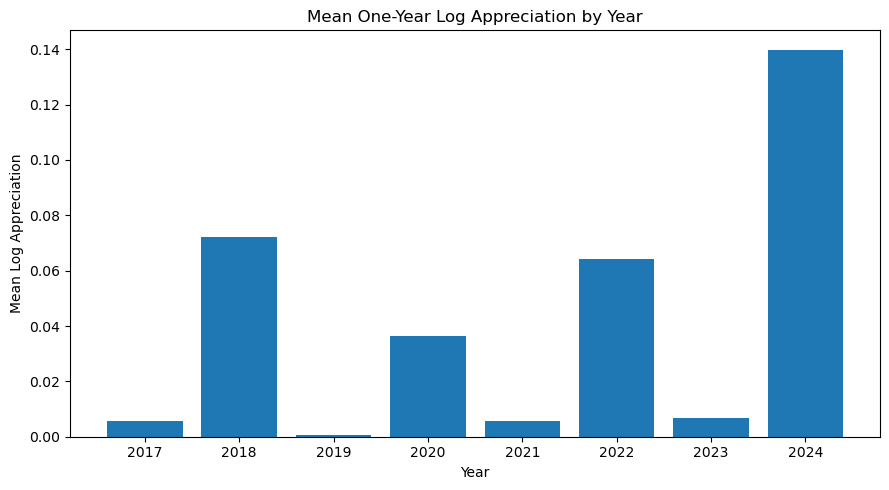

In [79]:
import matplotlib.pyplot as plt

year_log = clean_data.groupby("Year")["Log_Appreciation"].mean()

plt.figure(figsize=(9, 5))
plt.bar(year_log.index.astype(str), year_log.values)

plt.xlabel("Year")
plt.ylabel("Mean Log Appreciation")
plt.title("Mean One-Year Log Appreciation by Year")

plt.tight_layout()
plt.show()

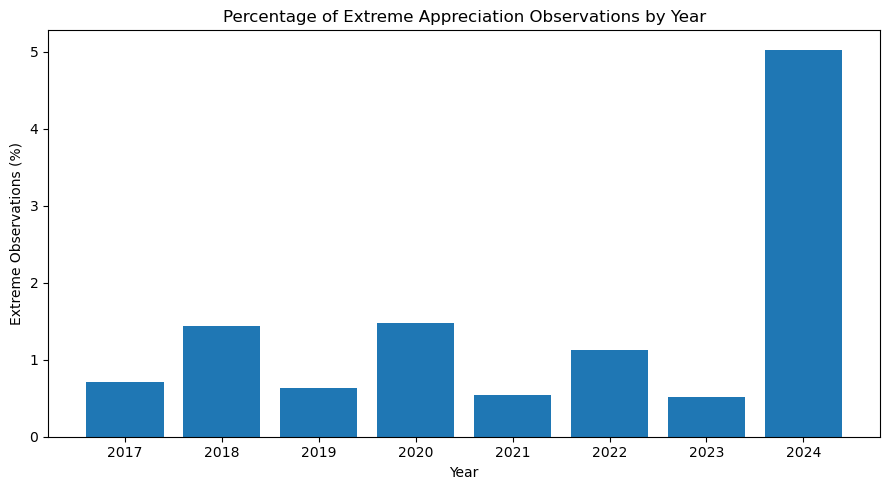

In [81]:
plt.figure(figsize=(9, 5))

plt.bar(
    year_extreme.index.astype(str),
    year_extreme["Extreme_Percent"]
)

plt.xlabel("Year")
plt.ylabel("Extreme Observations (%)")
plt.title("Percentage of Extreme Appreciation Observations by Year")

plt.tight_layout()
plt.show()

In [35]:
# Split the dataset
train_data = clean_data[clean_data["Year"] <= 2022].copy()
val_data = clean_data[clean_data["Year"] == 2023].copy()
test_data = clean_data[clean_data["Year"] == 2024].copy()

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

print("\nTarget distribution:")

display(
    pd.DataFrame({
        "Train": train_data["Log_Appreciation"].describe(),
        "Validation": val_data["Log_Appreciation"].describe(),
        "Test": test_data["Log_Appreciation"].describe()
    }).round(4)
)

Training: 746427
Validation: 120295
Testing: 120404

Target distribution:


,Train,Validation,Test
count,746427.0000,120295.0000,120404.0000
mean,0.0307,0.0066,0.1399
std,0.2128,0.1630,0.3269
min,-7.2226,-4.4086,-4.2373
25%,0.0000,0.0000,0.0000
50%,0.0000,0.0000,0.0700
75%,0.0396,0.0000,0.1625
max,7.3563,5.7379,6.0303


In [36]:
# Feature Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train = train_data[features]
X_val = val_data[features]
X_test = test_data[features]

y_train = train_data["Log_Appreciation"]
y_val = val_data["Log_Appreciation"]
y_test = test_data["Log_Appreciation"]

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("Number of features:", len(preprocessor.get_feature_names_out()))

Training: (746427, 549)
Validation: (120295, 549)
Testing: (120404, 549)
Number of features: 549


# Baseline Modeling

In [38]:
# Mean baseline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mean_pred = np.full(len(y_val), y_train.mean())

In [39]:
# Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_processed, y_train)

lr_pred = lr.predict(X_val_processed)

In [40]:
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_val, mean_pred),
        mean_absolute_error(y_val, lr_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, mean_pred)),
        np.sqrt(mean_squared_error(y_val, lr_pred))
    ],
    "R2": [
        r2_score(y_val, mean_pred),
        r2_score(y_val, lr_pred)
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,0.0421,0.1647,-0.0218
1,Linear Regression,0.0418,0.1646,-0.0206
